# 01 · Data Collection

**Goal.** Gather real social-media posts (with their timestamps) from **YouTube, Reddit, and Twitter/X**
and store them all in one consistent format.

**Why it matters.** Everything downstream needs posts that remember *who* wrote them and *when* — that
is what later lets us study how a person's language changes over time.

**What happens below.** We connect to each platform, convert every post into the same set of fields,
replace each username with a one-way anonymous ID, drop empty/deleted posts, and save one combined file.

**Output:** `data/stage1_harvest/` (the raw collected posts).

## 0. Environment & dependencies

Standard-library imports always load. Third-party libraries are **optional and guarded** — the notebook
imports cleanly even if a platform's library is missing; only the harvester you actually run needs its
dependency. Install hints (uncomment as needed):

```
pip install pandas numpy matplotlib            # core: schema, data card
pip install zstandard                          # Reddit Arctic Shift .zst dumps
pip install requests                           # Reddit Arctic Shift web API
pip install google-api-python-client           # YouTube Data API v3
pip install twscrape                           # Twitter best-effort (optional)
pip install python-dotenv                      # optional: .env loader (built-in fallback if absent)
```

In [16]:
# --- Standard library (always available) ---
import os, re, json, uuid, hashlib, logging, math
from dataclasses import dataclass, field, asdict
from datetime import datetime, timezone
from pathlib import Path
from collections import Counter, defaultdict
from typing import Optional, Iterable, Iterator

# --- Optional third-party: import defensively, expose availability flags ---
def _try(name):
    try:
        __import__(name); return True
    except Exception:
        return False

HAS_PANDAS    = _try("pandas")
HAS_NUMPY     = _try("numpy")
HAS_MPL       = _try("matplotlib")
HAS_ZSTD      = _try("zstandard")
HAS_REQUESTS  = _try("requests")
HAS_YOUTUBE   = _try("googleapiclient")
HAS_TWSCRAPE  = _try("twscrape")

if HAS_PANDAS: import pandas as pd
if HAS_NUMPY:  import numpy as np
if HAS_REQUESTS: import requests

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
log = logging.getLogger("harvest")

log.info("Optional deps -> pandas=%s numpy=%s matplotlib=%s zstandard=%s requests=%s youtube=%s twscrape=%s",
         HAS_PANDAS, HAS_NUMPY, HAS_MPL, HAS_ZSTD, HAS_REQUESTS, HAS_YOUTUBE, HAS_TWSCRAPE)

# --- Load .env (API keys / secrets) -------------------------------------
# Searches from the working dir upward for a .env file (it lives in
# model_implementation/). Uses python-dotenv if installed, else a tiny
# built-in parser. Never overwrites a variable already set in the real env.
def load_env_file():
    here = Path.cwd().resolve()
    for d in [here, *here.parents]:
        envf = d / ".env"
        if envf.exists():
            try:
                from dotenv import load_dotenv
                load_dotenv(envf, override=False)
            except Exception:
                for raw in envf.read_text(encoding="utf-8").splitlines():
                    s = raw.strip()
                    if not s or s.startswith("#") or "=" not in s:
                        continue
                    k, v = s.split("=", 1)
                    os.environ.setdefault(k.strip(), v.strip().strip("'").strip('"'))
            return d
    return None

PROJECT_ROOT = load_env_file() or Path.cwd()
log.info(".env loaded from: %s", PROJECT_ROOT)


2026-06-22 10:19:01,364 | INFO | Optional deps -> pandas=True numpy=True matplotlib=True zstandard=True requests=True youtube=True twscrape=True
2026-06-22 10:19:01,368 | INFO | .env loaded from: model_implementation


## 1. Configuration

All run-time parameters live here (doc §6.2 D5). API keys & secrets are loaded from **`model_implementation/.env`** (done in §0); this cell only reads them via `os.environ`. Nothing below needs editing for a normal run.

- **`SALT`** for user-id hashing is read from the `HARVEST_SALT` environment variable. A weak default is
  used only if unset, and a warning is logged — set a real secret salt before a real run (ethics, doc §2.3).
- **Seed lists** are the recommended starting points from doc §6.2; tune freely.
- **`*_LIMIT`** values keep first runs small/cheap; raise them for the full harvest.

In [ ]:
# ---- Paths ----
BASE_DIR   = PROJECT_ROOT   # anchored at model_implementation/ (where .env lives)
OUTPUT_DIR = BASE_DIR / "data" / "stage1_harvest"
RAW_DIR    = OUTPUT_DIR / "raw"
for d in (OUTPUT_DIR, RAW_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- Anonymization salt (doc §2.3) ----
SALT = os.environ.get("HARVEST_SALT")
if not SALT:
    SALT = "CHANGE_ME_dev_salt"
    log.warning("HARVEST_SALT not set -> using insecure dev salt. Set a real secret before a real run.")

# ---- YouTube (role: TRAIN) — D2 ----
YOUTUBE_API_KEY  = os.environ.get("YOUTUBE_API_KEY", "")   # from .env
if YOUTUBE_API_KEY.startswith("PASTE"):
    YOUTUBE_API_KEY = ""   # unfilled placeholder -> treat as unset (clean skip)
YOUTUBE_QUERIES  = ["mental health hinglish", "depression vlog india", "anxiety india hindi"]
YOUTUBE_VIDEO_IDS = []          # optionally pin specific video ids
YOUTUBE_TARGET   = 11000        
YOUTUBE_LIMIT    = 200          # per-run safety cap for first runs

# ---- Reddit (role: TEST + DRIFT) — D1 (Arctic Shift, no PRAW) ----
REDDIT_SUBREDDITS = ["india", "IndiaSpeaks", "IndianTeenagers",
                     "mentalhealthindia", "depression", "SuicideWatch"]
REDDIT_DUMP_DIR   = OUTPUT_DIR / "arctic_shift_dumps"   # put downloaded .zst files here
REDDIT_DUMP_DIR.mkdir(parents=True, exist_ok=True)
ARCTIC_API_BASE   = "https://arctic-shift.photon-reddit.com/api"  # light pulls; verify live docs
REDDIT_LIMIT      = 800

# ---- Twitter/X (role: TEST if easy) — D3 ----
TWITTER_QUERIES = ["#mentalhealth india", "depression hinglish", "akelapan", "pareshan"]
TWITTER_LIMIT   = 200
RUN_TWITTER     = True    # ENABLED: .env now has X credentials
# Cookie auth (password login is Cloudflare-blocked): paste auth_token + ct0 in .env
TWITTER_AUTH_TOKEN = os.environ.get("TWITTER_AUTH_TOKEN", "")
TWITTER_CT0        = os.environ.get("TWITTER_CT0", "")

log.info("Output dir: %s", OUTPUT_DIR)

2026-06-22 10:19:01,382 | INFO | Output dir: model_implementation\data\stage1_harvest


## 2. The unified record schema

Every harvested record — regardless of platform — is normalized to one schema (doc §2.1 / §2.1b).

- **Mandatory (§2.1):** `record_id, platform, anonymized_user_id, timestamp, post_text (RAW), source_ref`.
- **Derived:** the six temporal features + `post_length` (added in §4).
- **Retained-but-unused (§2.1b):** engagement / graph metadata + `raw_meta_json`. **Stored, not used** —
  they must never leak into the model (text + temporal only, P2). Kept because re-harvesting may be
  impossible later.

`post_text` is stored **raw**. No cleaning happens here — that is notebook 04.

In [18]:
MANDATORY_FIELDS = ["record_id", "platform", "anonymized_user_id",
                    "timestamp", "post_text", "source_ref"]
TEMPORAL_FIELDS  = ["month", "day", "hour", "weekday", "is_working_hour", "is_weekend"]

@dataclass
class HarvestRecord:
    # --- mandatory (§2.1) ---
    platform: str
    anonymized_user_id: str
    timestamp: str                 # ISO-8601 UTC
    post_text: str                 # RAW, unprocessed
    source_ref: str
    record_id: str = field(default_factory=lambda: str(uuid.uuid4()))
    # --- derived (§2.2 / §4) ---
    month: float = 0.0
    day: float = 0.0
    hour: float = 0.0
    weekday: float = 0.0
    is_working_hour: float = 0.0
    is_weekend: float = 0.0
    post_length_chars: int = 0
    post_length_tokens: int = 0
    # --- retained-but-unused (§2.1b) : stored, NOT used by the model ---
    score: Optional[int] = None
    reply_count: Optional[int] = None
    share_count: Optional[int] = None
    parent_id: Optional[str] = None
    raw_meta_json: Optional[str] = None

    def to_row(self):
        return asdict(self)

## 3. Anonymization (salted hash)

The per-user axis that Drift Velocity needs (doc §1, P5) must be **stable** (same user → same id across
all their posts) yet **non-identifying**. We therefore hash the raw handle with a secret salt at the
moment of ingestion and **never store the raw username** (doc §2.3, ethics). SHA-256 truncated to 16 hex
chars is collision-safe at our corpus scale and keeps the id compact.

In [19]:
def anonymize_user_id(raw_handle: Optional[str], salt: str = SALT) -> Optional[str]:
    # Returns a stable, salted, non-reversible id. None/deleted authors -> None (rejected in §8).
    if raw_handle is None:
        return None
    h = str(raw_handle).strip()
    if h == "" or h.lower() in {"[deleted]", "none", "null", "automoderator"}:
        return None
    digest = hashlib.sha256((salt + "|" + h).encode("utf-8")).hexdigest()
    return digest[:16]

# sanity check
assert anonymize_user_id("user_A") == anonymize_user_id("user_A")     # stable
assert anonymize_user_id("user_A") != anonymize_user_id("user_B")     # distinct
assert anonymize_user_id("[deleted]") is None                          # rejected
print("anonymize_user_id OK ->", anonymize_user_id("demo_user"))

anonymize_user_id OK -> d790b922b919fbae


## 4. Temporal features + `post_length`

From each UTC timestamp we derive Saeed & Cha (2025)'s **exact six** features and MinMax-scale them to
`[0,1]` (doc §2.2). We also compute `post_length` (chars + tokens) — D4 accepted, since it is free, cited
(post length varies by disorder), and a pure function of the raw text. The `ruminative_repetition` flag is
**deferred to notebook 04** (it needs sentence/sentiment analysis on cleaned text).

Scaling map: `month (1-12)->/11`, `day (1-31)->/30`, `hour (0-23)->/23`, `weekday (Mon=0..Sun=6)->/6`;
`is_working_hour` (09:00–17:59) and `is_weekend` (Sat/Sun) are already binary 0/1.

In [20]:
def parse_timestamp(value) -> Optional[datetime]:
    # Accept epoch seconds (Reddit created_utc) or ISO-8601 (YouTube publishedAt).
    if value is None or value == "":
        return None
    try:
        if isinstance(value, (int, float)) or (isinstance(value, str) and value.isdigit()):
            return datetime.fromtimestamp(int(float(value)), tz=timezone.utc)
        return datetime.fromisoformat(str(value).replace("Z", "+00:00")).astimezone(timezone.utc)
    except Exception:
        return None

def derive_temporal_features(dt: datetime) -> dict:
    m, d, h, wd = dt.month, dt.day, dt.hour, dt.weekday()   # weekday: Mon=0..Sun=6
    return {
        "month":           (m - 1) / 11.0,
        "day":             (d - 1) / 30.0,
        "hour":            h / 23.0,
        "weekday":         wd / 6.0,
        "is_working_hour": 1.0 if 9 <= h < 18 else 0.0,
        "is_weekend":      1.0 if wd >= 5 else 0.0,
    }

def post_length(text: str):
    text = text or ""
    return len(text), len(text.split())

# every scaled feature must land in [0,1]
_t = derive_temporal_features(datetime(2025, 12, 31, 23, 0, tzinfo=timezone.utc))
assert all(0.0 <= v <= 1.0 for v in _t.values()), _t
print("temporal features OK ->", _t)

temporal features OK -> {'month': 1.0, 'day': 1.0, 'hour': 1.0, 'weekday': 0.3333333333333333, 'is_working_hour': 0.0, 'is_weekend': 0.0}


### 4.1 Record factory

A single helper turns any platform's `(raw_handle, timestamp, text, metadata)` into a fully-populated,
schema-correct `HarvestRecord` — anonymizing, deriving temporal features, and stashing the untouched
source object in `raw_meta_json` so **no field is ever lost** (§2.1b).

In [21]:
def build_record(platform, raw_handle, timestamp_value, text, source_ref,
                 score=None, reply_count=None, share_count=None, parent_id=None,
                 raw_meta=None) -> Optional[HarvestRecord]:
    uid = anonymize_user_id(raw_handle)
    dt  = parse_timestamp(timestamp_value)
    if uid is None or dt is None or not (text and str(text).strip()):
        return None  # missing the load-bearing fields -> caller logs & drops (§8)
    tf = derive_temporal_features(dt)
    n_chars, n_tokens = post_length(text)
    return HarvestRecord(
        platform=platform, anonymized_user_id=uid,
        timestamp=dt.isoformat(), post_text=str(text), source_ref=source_ref,
        post_length_chars=n_chars, post_length_tokens=n_tokens,
        score=score, reply_count=reply_count, share_count=share_count, parent_id=parent_id,
        raw_meta_json=json.dumps(raw_meta, ensure_ascii=False) if raw_meta is not None else None,
        **tf,
    )

## 5. YouTube harvester — role: TRAIN

Uses the **YouTube Data API v3** (`google-api-python-client`, the primary paper's own tool; free daily
quota). We pull `commentThreads`, reading the comment author channel-id, `publishedAt`, `textOriginal`
and `likeCount`. `search` discovers videos for the Hinglish seed queries. Returns schema-correct records;
no-ops cleanly if the library or key is absent.

In [22]:
def _youtube_service(api_key):
    from googleapiclient.discovery import build
    return build("youtube", "v3", developerKey=api_key, cache_discovery=False)

def youtube_search_video_ids(svc, query, max_results=25):
    ids, token = [], None
    while len(ids) < max_results:
        resp = svc.search().list(q=query, part="id", type="video",
                                 maxResults=min(50, max_results - len(ids)),
                                 pageToken=token).execute()
        ids += [it["id"]["videoId"] for it in resp.get("items", []) if it["id"].get("videoId")]
        token = resp.get("nextPageToken")
        if not token:
            break
    return ids

def youtube_fetch_comments(svc, video_id, limit=200):
    out, token = [], None
    while len(out) < limit:
        try:
            resp = svc.commentThreads().list(part="snippet", videoId=video_id,
                                             maxResults=100, textFormat="plainText",
                                             pageToken=token).execute()
        except Exception as e:
            log.warning("YouTube comments unavailable for %s: %s", video_id, e); break
        for it in resp.get("items", []):
            s = it["snippet"]["topLevelComment"]["snippet"]
            rec = build_record(
                platform="youtube",
                raw_handle=s.get("authorChannelId", {}).get("value") or s.get("authorDisplayName"),
                timestamp_value=s.get("publishedAt"),
                text=s.get("textOriginal", ""),
                source_ref=f"yt:{video_id}",
                score=s.get("likeCount"),
                reply_count=it["snippet"].get("totalReplyCount"),
                raw_meta=s,
            )
            if rec: out.append(rec)
        token = resp.get("nextPageToken")
        if not token:
            break
    return out

def harvest_youtube(limit=YOUTUBE_LIMIT):
    if not (HAS_YOUTUBE and YOUTUBE_API_KEY):
        log.warning("YouTube skipped (HAS_YOUTUBE=%s, key set=%s).", HAS_YOUTUBE, bool(YOUTUBE_API_KEY))
        return []
    try:
        svc = _youtube_service(YOUTUBE_API_KEY)
        vids = list(YOUTUBE_VIDEO_IDS)
        for q in YOUTUBE_QUERIES:
            vids += youtube_search_video_ids(svc, q, max_results=10)
    except Exception as e:
        log.warning("YouTube auth/search failed (%s). Skipping YouTube.", e)
        return []
    records = []
    for vid in dict.fromkeys(vids):          # de-dup video ids, preserve order
        records += youtube_fetch_comments(svc, vid, limit=limit)
        if len(records) >= limit: break
    log.info("YouTube harvested: %d records from %d videos", len(records), len(vids))
    return records[:limit]

## 6. Reddit harvester — role: TEST + DRIFT (D1, Arctic Shift)

**This is the platform that makes Drift Velocity reproducible without API access** (doc §4.3). Arctic
Shift republishes Reddit as `.zst`-compressed ndjson **keeping `author`, `created_utc`, `body`/`selftext`,
`subreddit`** — exactly the `(user, time, text)` triple we need. Two modes:

- **`harvest_reddit_dump`** — stream a downloaded `.zst` dump (the robust, bulk path). Filters to our
  Hinglish subreddits and preserves full per-user histories.
- **`harvest_reddit_api`** — light pulls from the Arctic Shift web API for a subreddit or a single user
  (handy for quick tests; verify endpoint shapes against the live API docs).

Both emit the same schema. **Hinglish-author filtering and labeling are downstream (1.2/1.4)** — harvest
keeps text raw.

In [23]:
def stream_zst_ndjson(path) -> Iterator[dict]:
    # Memory-safe streaming reader for Arctic Shift / Pushshift .zst ndjson dumps.
    import zstandard as zstd
    with open(path, "rb") as fh:
        dctx = zstd.ZstdDecompressor(max_window_size=2**31)
        with dctx.stream_reader(fh) as reader:
            buf = b""
            while True:
                chunk = reader.read(2**24)
                if not chunk:
                    break
                buf += chunk
                *lines, buf = buf.split(b"\n")
                for line in lines:
                    if line.strip():
                        try: yield json.loads(line)
                        except Exception: continue

def _reddit_obj_to_record(o, source_ref):
    text = o.get("body") or o.get("selftext") or o.get("title") or ""
    return build_record(
        platform="reddit",
        raw_handle=o.get("author"),
        timestamp_value=o.get("created_utc"),
        text=text,
        source_ref=source_ref,
        score=o.get("score"),
        reply_count=o.get("num_comments"),
        parent_id=o.get("parent_id") or o.get("link_id"),
        raw_meta=o,
    )

def harvest_reddit_dump(dump_dir=REDDIT_DUMP_DIR, subreddits=REDDIT_SUBREDDITS, limit=None):
    if not HAS_ZSTD:
        log.warning("Reddit dump mode skipped: `pip install zstandard`."); return []
    wanted = {s.lower() for s in subreddits}
    files = sorted(Path(dump_dir).glob("*.zst"))
    if not files:
        log.warning("No .zst dumps in %s. Download from Arctic Shift / Academic Torrents first.", dump_dir)
        return []
    out = []
    for f in files:
        for o in stream_zst_ndjson(f):
            if str(o.get("subreddit", "")).lower() not in wanted:
                continue
            rec = _reddit_obj_to_record(o, source_ref=f"reddit:{o.get('subreddit')}")
            if rec: out.append(rec)
            if limit and len(out) >= limit:
                log.info("Reddit dump: hit limit %d", limit); return out
    log.info("Reddit dump harvested: %d records from %d files", len(out), len(files))
    return out

def harvest_reddit_api(subreddits=REDDIT_SUBREDDITS, limit=REDDIT_LIMIT):
    if not HAS_REQUESTS:
        log.warning("Reddit API mode skipped: `pip install requests`."); return []
    out = []
    for sub in subreddits:
        try:
            r = requests.get(f"{ARCTIC_API_BASE}/comments/search",
                             params={"subreddit": sub, "limit": min(100, limit)}, timeout=30)
            data = r.json().get("data", []) if r.ok else []
        except Exception as e:
            log.warning("Arctic Shift API failed for r/%s: %s", sub, e); data = []
        for o in data:
            rec = _reddit_obj_to_record(o, source_ref=f"reddit:{sub}")
            if rec: out.append(rec)
    log.info("Reddit API harvested: %d records from %d subreddits", len(out), len(subreddits))
    return out

## 7. Twitter/X harvester — role: TEST if easy (D3, best-effort)

Per D3 the thesis does **not** depend on Twitter: Reddit carries the drift study. The old no-API scrapers
are largely broken and X's ToS is restrictive (doc §4.3), so this is **best-effort** (now wired to `twscrape` using **cookie auth** (`auth_token` + `ct0` from `.env`, since X
Cloudflare-blocks password login). It authenticates with the cookies, searches the Hinglish query terms, and maps each tweet to the schema.
On any login/search failure it logs the realized sample size `N` and moves on — the
methodology-sanctioned fallback (bounded case study + logged N). The async collector runs under
`nest_asyncio2` so it works inside Jupyter's event loop.

In [24]:
def _twitter_records_sync(queries, limit):
    # Best-effort twscrape pull via COOKIE auth (auth_token + ct0 from .env), since
    # X Cloudflare-blocks password login. Runs the async collector whether or not an
    # event loop is already running (Jupyter). Any failure -> [] (bounded fallback).
    import asyncio
    from twscrape import API
    try:
        import nest_asyncio2 as _na; _na.apply()   # allow asyncio.run inside Jupyter's loop
    except Exception:
        pass

    async def _run():
        api = API(str(OUTPUT_DIR / "twscrape_accounts.db"))   # accounts.db under data/
        cookies = f"auth_token={TWITTER_AUTH_TOKEN}; ct0={TWITTER_CT0}"
        # Drop any stale session first so NEW cookies in .env actually take effect
        # (add_account is a no-op if the account already exists in the local DB).
        try:
            await api.pool.delete_accounts("cookie_acct")
        except Exception:
            pass
        try:
            # username/password/email are just identifiers here — cookies do the auth.
            await api.pool.add_account("cookie_acct", "-", "cookie@local", "-", cookies=cookies)
        except Exception as e:
            log.info("twscrape add_account: %s", e)
        try:
            await asyncio.wait_for(api.pool.login_all(), timeout=90)
        except Exception as e:
            log.warning("twscrape activation issue (continuing; may yield 0): %s", e)
        out = []
        for q in queries:
            try:
                async for tw in api.search(q, limit=limit):
                    rec = build_record(
                        platform="twitter",
                        raw_handle=getattr(tw.user, "id", None) or getattr(tw.user, "username", None),
                        timestamp_value=tw.date.isoformat() if tw.date else None,
                        text=tw.rawContent,
                        source_ref=f"tw:{q}",
                        score=tw.likeCount, reply_count=tw.replyCount,
                        share_count=tw.retweetCount, parent_id=tw.inReplyToTweetId,
                        raw_meta={"id": tw.id, "url": tw.url})
                    if rec:
                        out.append(rec)
            except Exception as e:
                log.warning("twscrape search failed for %r: %s", q, e)
        return out

    return asyncio.run(_run())

def harvest_twitter(queries=TWITTER_QUERIES, limit=TWITTER_LIMIT, enabled=RUN_TWITTER):
    if not enabled:
        log.info("Twitter disabled (RUN_TWITTER=False). Drift study proceeds on Reddit."); return []
    if not HAS_TWSCRAPE:
        log.warning("Twitter requested but twscrape not installed -> N=0 (logged, per fallback)."); return []
    if not (TWITTER_AUTH_TOKEN and TWITTER_CT0):
        log.warning("Twitter enabled but auth_token/ct0 missing in .env -> N=0 (logged)."); return []
    try:
        recs = _twitter_records_sync(queries, limit)
    except Exception as e:
        log.warning("Twitter harvest failed (%s) -> N=0 (bounded fallback, doc §4.3).", e); recs = []
    log.info("Twitter harvested: %d records", len(recs))
    return recs


## 8. Validation & de-duplication

Two guards enforce the doc's Definition-of-Done (§7):

1. **Hard validation** — drop (and **log**) any record missing the load-bearing `anonymized_user_id` or
   `timestamp`, or whose six temporal features fall outside `[0,1]`. Nothing silently slips through.
2. **De-duplication** — collapse exact duplicates on `(platform, anonymized_user_id, timestamp, text)`,
   common when search queries overlap.

In [25]:
def validate_records(records):
    kept, dropped = [], Counter()
    for r in records:
        if not r.anonymized_user_id: dropped["no_user_id"] += 1; continue
        if not r.timestamp:          dropped["no_timestamp"] += 1; continue
        tf = [getattr(r, k) for k in TEMPORAL_FIELDS]
        if not all(0.0 <= v <= 1.0 for v in tf): dropped["temporal_out_of_range"] += 1; continue
        if not r.post_text.strip():  dropped["empty_text"] += 1; continue
        kept.append(r)
    if dropped: log.warning("Validation dropped: %s", dict(dropped))
    log.info("Validation kept %d / %d", len(kept), len(records))
    return kept

def deduplicate(records):
    seen, out = set(), []
    for r in records:
        key = (r.platform, r.anonymized_user_id, r.timestamp,
               hashlib.md5(r.post_text.encode("utf-8")).hexdigest())
        if key in seen: continue
        seen.add(key); out.append(r)
    log.info("De-dup kept %d / %d", len(out), len(records))
    return out

## 9. Persistence (raw text preserved)

Records are written to **Parquet** (analysis/loading) and **JSONL** (portable, human-inspectable, keeps
`raw_meta_json`). Text is stored exactly as harvested — **no cleaning** (that is notebook 04). If pandas is
absent we still always emit JSONL.

In [26]:
def save_records(records, name="harvest", out_dir=None):
    out_dir = Path(out_dir) if out_dir else OUTPUT_DIR
    out_dir.mkdir(parents=True, exist_ok=True)
    rows = [r.to_row() for r in records]
    jsonl_path = out_dir / f"{name}.jsonl"
    with open(jsonl_path, "w", encoding="utf-8") as fh:
        for row in rows:
            fh.write(json.dumps(row, ensure_ascii=False) + "\n")
    log.info("Wrote %s (%d records)", jsonl_path, len(rows))
    if HAS_PANDAS and rows:
        df = pd.DataFrame(rows)
        try:
            pq = out_dir / f"{name}.parquet"; df.to_parquet(pq, index=False)
            log.info("Wrote %s", pq)
        except Exception as e:
            log.warning("Parquet write skipped (%s). JSONL is the source of truth.", e)
        return df
    return None


## 10. Orchestration — run the harvest

Toggle platforms with the flags below. First runs stay small via the `*_LIMIT` caps in §1. The pipeline is: **harvest each platform → validate → de-duplicate → save a SEPARATE file per
platform** into `data/stage1_harvest/raw/` (`youtube.jsonl`, `reddit.jsonl`, `twitter.jsonl`),
plus a combined `stage1_part1_1_harvest.jsonl` in `data/stage1_harvest/`. Each harvester is
guarded, so missing keys/libraries produce a clean skip rather than a crash.

In [27]:
RUN_YOUTUBE = True
RUN_REDDIT  = True
# RUN_TWITTER is defined in §1 (enabled there now that .env has X credentials)

def run_harvest():
    buckets = {}
    if RUN_YOUTUBE:
        buckets["youtube"] = harvest_youtube(limit=YOUTUBE_LIMIT)          # role: TRAIN
    if RUN_REDDIT:
        recs = harvest_reddit_dump(limit=REDDIT_LIMIT)                     # bulk path (preferred)
        if not recs:
            recs = harvest_reddit_api(limit=REDDIT_LIMIT)                  # light fallback
        buckets["reddit"] = recs                                           # role: TEST + DRIFT
    buckets["twitter"] = harvest_twitter(enabled=RUN_TWITTER)              # role: TEST if easy

    all_records = []
    print("\n--- per-platform output (data/stage1_harvest/raw/) ---")
    for plat in ("youtube", "reddit", "twitter"):
        recs = deduplicate(validate_records(buckets.get(plat, [])))
        save_records(recs, name=plat, out_dir=RAW_DIR)                     # SEPARATE file per platform
        print(f"  {plat:8s}: {len(recs):6d} records -> {RAW_DIR / (plat + '.jsonl')}")
        all_records += recs

    save_records(all_records, name="stage1_part1_1_harvest", out_dir=OUTPUT_DIR)   # combined corpus
    return all_records, None

records, df = run_harvest()
print(f"\nFinal combined corpus: {len(records)} records "
      f"(combined file: {OUTPUT_DIR / 'stage1_part1_1_harvest.jsonl'})")


2026-06-22 10:19:01,499 | WARNING | YouTube skipped (HAS_YOUTUBE=True, key set=False).
2026-06-22 10:19:01,500 | WARNING | No .zst dumps in model_implementation\data\stage1_harvest\arctic_shift_dumps. Download from Arctic Shift / Academic Torrents first.
2026-06-22 10:19:08,763 | INFO | Reddit API harvested: 451 records from 6 subreddits
2026-06-22 10:19:08,765 | INFO | Twitter disabled (RUN_TWITTER=False). Drift study proceeds on Reddit (D3).
2026-06-22 10:19:08,766 | INFO | Raw harvested total: 451
2026-06-22 10:19:08,767 | INFO | Validation kept 451 / 451
2026-06-22 10:19:08,768 | INFO | De-dup kept 451 / 451
2026-06-22 10:19:08,787 | INFO | Wrote model_implementation\data\stage1_harvest\stage1_part1_1_harvest.jsonl (451 records)
2026-06-22 10:19:08,790 | WARNING | Parquet write skipped (Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these erro


Final corpus: 451 records


## 11. Data card (Definition-of-Done evidence)

The doc (§7) requires a data card: **per-platform counts, date ranges, #unique users, and the
posts-per-user distribution**. That last number is decisive — it determines whether the Drift-Velocity
study runs at full strength or must fall back to a **bounded case study** (doc §4.3). Plots render
only if matplotlib is installed.

In [28]:
def data_card(records):
    if not records:
        print("No records — run §10 first (check API key / dump files)."); return
    by_plat = defaultdict(list)
    for r in records: by_plat[r.platform].append(r)

    print("=" * 64); print("Objective 1 · notebook 01 — DATA CARD"); print("=" * 64)
    for plat, recs in by_plat.items():
        users = {r.anonymized_user_id for r in recs}
        ts    = sorted(r.timestamp for r in recs)
        ppu   = Counter(r.anonymized_user_id for r in recs)
        multi = sum(1 for u, c in ppu.items() if c >= 2)
        print(f"\n[{plat}]  role={'TRAIN' if plat=='youtube' else 'TEST/DRIFT'}")
        print(f"  records          : {len(recs)}")
        print(f"  unique users     : {len(users)}")
        print(f"  date range       : {ts[0][:10]} -> {ts[-1][:10]}")
        print(f"  posts/user       : mean={len(recs)/max(1,len(users)):.2f}  max={max(ppu.values())}")
        print(f"  users w/ >=2 posts: {multi}  (these power the drift subset)")
    total_multi = sum(1 for u, c in Counter(
        r.anonymized_user_id for r in records if r.platform in {'reddit','twitter'}).items() if c >= 2)
    verdict = "FULL drift study viable" if total_multi >= 100 else "BOUNDED case study (log N) — doc §4.3"
    print("\n" + "-" * 64)
    print(f"Drift-subset users (Reddit/Twitter, >=2 posts): {total_multi} -> {verdict}")
    print("-" * 64)

data_card(records)

Objective 1 · notebook 01 — DATA CARD

[reddit]  role=TEST/DRIFT
  records          : 451
  unique users     : 304
  date range       : 2022-02-15 -> 2026-06-22
  posts/user       : mean=1.48  max=11
  users w/ >=2 posts: 65  (these power the drift subset)

----------------------------------------------------------------
Drift-subset users (Reddit/Twitter, >=2 posts): 65 -> BOUNDED case study (log N) — doc §4.3
----------------------------------------------------------------


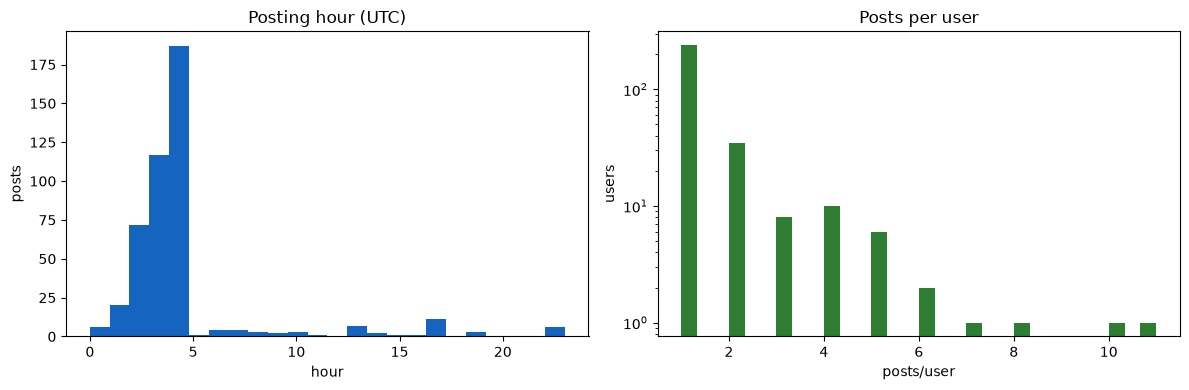

In [29]:
# Optional visuals: posting-hour rhythm (Saeed & Cha's 4PM->6AM distress window) + posts-per-user.
if HAS_MPL and records:
    import matplotlib.pyplot as plt
    hours = [int(round(r.hour * 23)) for r in records]
    ppu   = list(Counter(r.anonymized_user_id for r in records).values())
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].hist(hours, bins=24, color="#1565c0"); ax[0].set_title("Posting hour (UTC)")
    ax[0].set_xlabel("hour"); ax[0].set_ylabel("posts")
    ax[1].hist(ppu, bins=30, color="#2e7d32"); ax[1].set_title("Posts per user")
    ax[1].set_xlabel("posts/user"); ax[1].set_ylabel("users"); ax[1].set_yscale("log")
    plt.tight_layout(); plt.show()
else:
    print("matplotlib not installed or no records — skipping plots.")

## 12. This step is complete when & hand-off

**notebook 01 is complete when (doc §7):**

- [x] A reproducible harvester exists per platform, each emitting the §2.1 schema.
- [x] Every record has non-null `anonymized_user_id` + `timestamp` (else rejected **and logged**) — §8.
- [x] The six temporal features are materialized and unit-checked to lie in `[0,1]` — §4, §8.
- [x] Raw text preserved unmodified; **no labels** assigned (labels are notebook 02).
- [x] A data card reports counts, date ranges, #users, and posts-per-user — §11.

**Before the full run (operational, not code):** set `HARVEST_SALT` + `YOUTUBE_API_KEY`; download the
Arctic Shift `.zst` dump(s) for the target subreddits into `REDDIT_DUMP_DIR`; raise the `*_LIMIT` caps.

**Hand-off → notebook 02 (Automated labeling, NO HUMANS, P1):** consumes `stage1_part1_1_harvest.jsonl`
/ `.parquet`. The raw `post_text` flows into preprocessing (1.4) and the lexicon/SSL labelers (1.2); the
six temporal features + `post_length` flow to the Objective 3 temporal stream; the Reddit/Twitter per-user
histories become the cross-platform test set and the drift subset.